# Settings

In [177]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/001_params.json"#/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse/params.json"

file_paths = [
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_001_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_01_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_1_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/003_bf_rect.npy"

    #"./data_bf/master_thesis/beamformed_apodized/001_bf_results_interpolated_.npy",
    #"./data_bf/master_thesis/beamformed_apodized/001_bf_results_interpolated_hamming.npy",
    #"./data_bf/master_thesis/beamformed_apodized/001_bf_results_interpolated_angles_.npy",
    #"./data_bf/master_thesis/beamformed_apodized/001_bf_results_interpolated_angles_hamming.npy",
    #"./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_nsi_nsi.npy",
    #"./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_angles_nsi_nsi.npy",
    #"./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_angles_nsi_hamming_nsi.npy"

    # "./data_bf/master_thesis/ref_comparison/beamformed_apodized/001_bf_results_interpolated_angles_ref1_.npy",
    # "./data_bf/master_thesis/ref_comparison/beamformed_apodized/001_bf_results_interpolated_angles_ref2_.npy",
    # "./data_bf/master_thesis/ref_comparison/beamformed_apodized/001_bf_results_interpolated_angles_ref3_.npy",

    # "./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_angles_nsi_ref1_nsi.npy",
    # "./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_angles_nsi_ref2_test_nsi.npy",
    # "./data_filtered/master_thesis/filtered_bf/001_bff_results_interpolated_angles_nsi_ref3_nsi.npy",

    #"./data_bf/master_thesis_test/beamformed_apodized/001_bf_results_interpolated_angles_rectangle.npy",
    #"./data_bf/master_thesis_test/beamformed_apodized/001_bf_results_interpolated_angles_hamming.npy",
    #"./data_bf/master_thesis_test/beamformed_apodized/001_bf_results_interpolated_angles_nsi_zm.npy",
    #"./data_bf/master_thesis_test/beamformed_apodized/001_bf_results_interpolated_angles_nsi_dc1.npy",
    #"./data_bf/master_thesis_test/beamformed_apodized/001_bf_results_interpolated_angles_nsi_dc2.npy",
    #"./data_filtered/master_thesis_test/filtered_bf/001_bff_results_interpolated_angles_nsi.npy"

    #? new res stuff

    #* angles
    "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_.npy",
    "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_hamming.npy",
    "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_rectangle.npy",
    #"./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_zm.npy",
    # "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_dc1.npy",
    # "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_angles_dc2.npy",
    "./data_filtered/master_thesis_newres/filtered_bf/001_bff_results_interpolated_angles_nsi.npy",

    #* no angles

    #"./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_.npy",
    #"./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_hamming.npy",
    #"./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_rectangle.npy",
    #"./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_zm.npy",
    # "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_dc1.npy",
    # "./data_bf/master_thesis_newres/beamformed_apodized/001_bf_results_interpolated_nsi_dc2.npy",
    "./data_filtered/master_thesis_newres/filtered_bf/001_bff_results_interpolated_nsi.npy",

    #* objects compare

    "./data_filtered/master_thesis_newres/filtered_bf/001_bff_results_interpolated_angles_ref2_nsi.npy"

]

visualizing_upsampled_data = True

# Imports

In [178]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [179]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [180]:
def add_extra_params(params, C):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    samples = params["rf"]["samples"] if not visualizing_upsampled_data else params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["sampling_rate"] if not visualizing_upsampled_data else params["rf"]["upsampled_sampling_rate"]

    max_acquisition_depth = C * (1 / sampling_rate * samples) / 2
    params["image"]["samples_depth"] = int(max_acquisition_depth / params["image"]["dz"])
    params["image"]["samples_lateral"] = int(params["array"]["length"] * params["array"]["pitch"] / params["image"]["dx"])

    return params

In [181]:

params = load_parameters(parameters_file_path)

C = params["rf"]["C"] #speed of sound

params = add_extra_params(params, C)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling

# Import bf image data

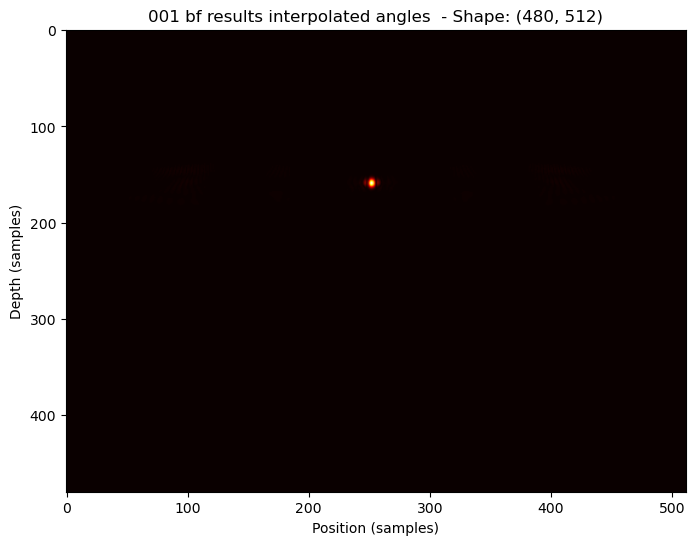

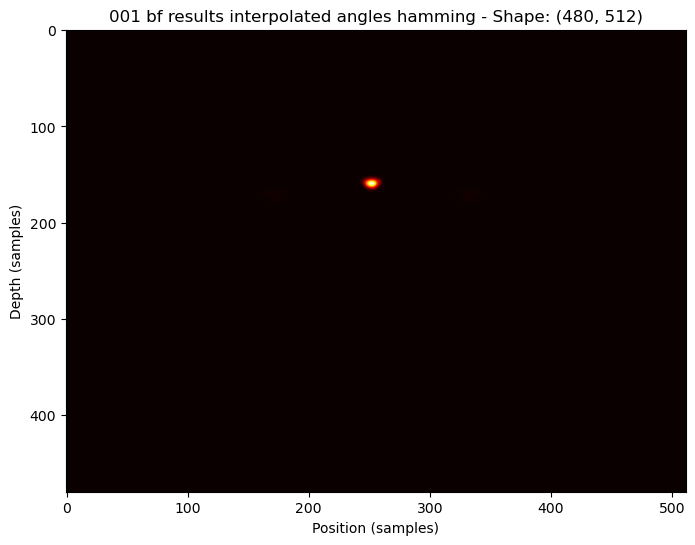

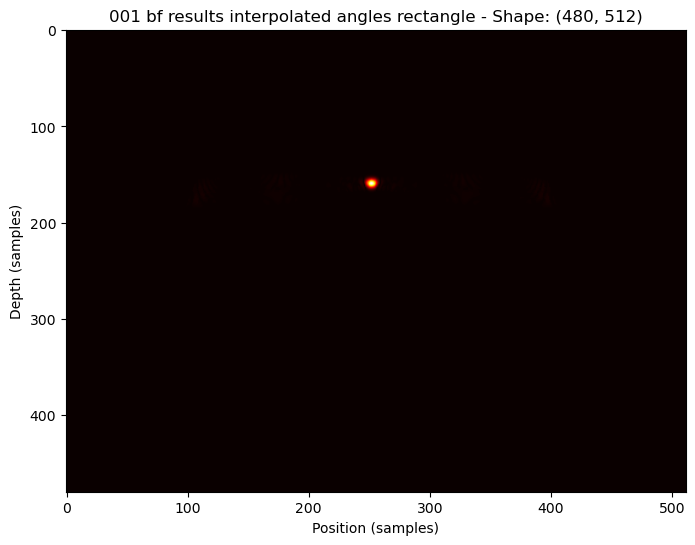

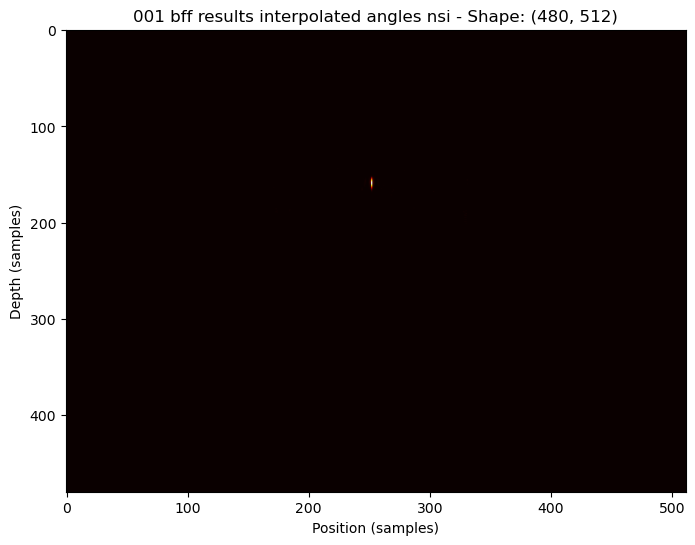

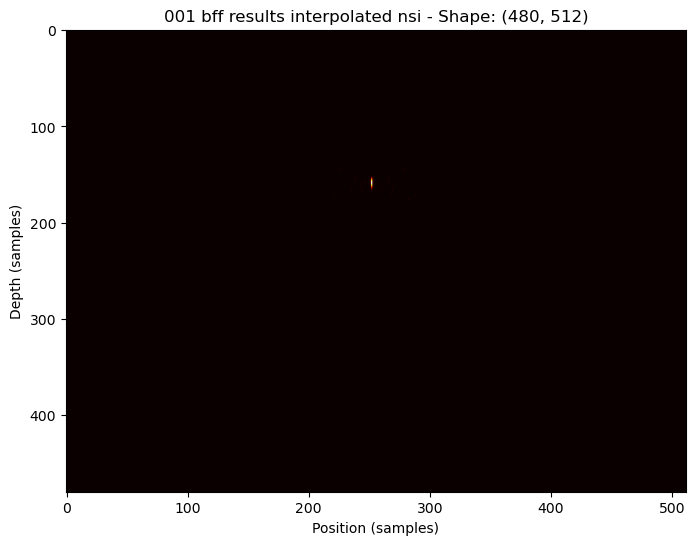

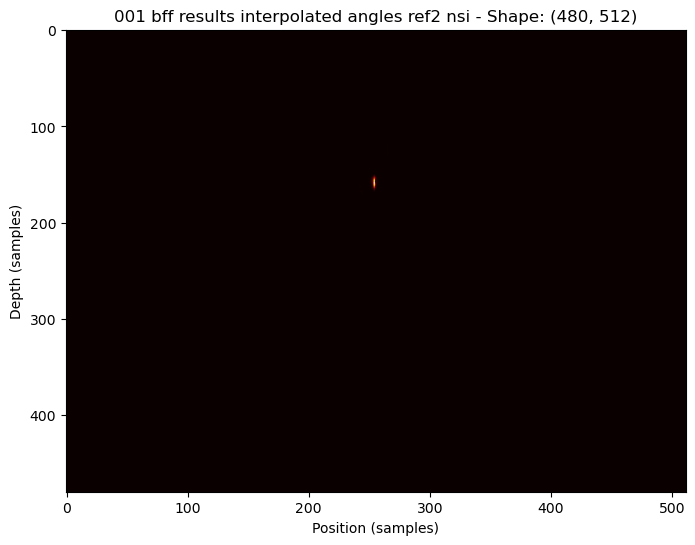

In [182]:
data = np.load(file_paths[0])

bf_matrices = np.zeros(
        (
        data.shape[0],
        data.shape[1], 
        len(file_paths)
        )
    )
labels = []

for idx, file_path in enumerate(file_paths):
    
    data = np.load(file_path)
    data = np.squeeze(data)

    plt.figure(figsize=(8, 6))
    plt.imshow(np.abs(data), aspect='auto', cmap='hot')
    plt.xlabel("Position (samples)")
    plt.ylabel("Depth (samples)")

    bf_matrices[:, :, idx] = data

    label = file_path.strip().split("/")[-1].split(".")[0].replace("_", " ")

    plt.title(f"{label} - Shape: {data.shape}")

    labels.append(label)

    plt.show()

# Comparaison

In [183]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

In [184]:
def compare_resolutions(bf_matrices, step_size, lateral_step, labels, profile_x0, profile_y0, lat_len, axial_len, ymin=None, ymax=None, xmin=None, xmax=None):
    
    #viz
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].hlines(-6, 0, 0,colors='r', linestyles='--', label='Half max value (-6dB)')
    axes[1].hlines(-6, 0, 0, colors='r', linestyles='--', label='Half max value (-6dB)')


    for i in range(bf_matrices.shape[2]):
        
        # lat = bf_matrices[int(profile_x0 - lat_len/2):int(profile_x0 + lat_len/2),profile_y0,i]
        # axial = bf_matrices[profile_x0, int(profile_y0 - axial_len): int(profile_y0 + axial_len),i]

        lat = bf_matrices[profile_y0, int(profile_x0 - lat_len/2):int(profile_x0 + lat_len/2), i]
        axial = bf_matrices[int(profile_y0 - axial_len/2):int(profile_y0 + axial_len/2), profile_x0, i]


        lateral_profile = 20 * np.log10(np.abs(lat) / np.max(np.abs(lat)))
        axial_profile = 20 * np.log10(np.abs(axial) / np.max(np.abs(axial)))

        # print(f"Max value of lateral profile {i}: {np.max(lateral_profile)} dB")
        # print(f"Max value of axial profile {i}: {np.max(axial_profile)} dB")
        # print(f"Min value of lateral profile {i}: {np.min(lateral_profile)} dB")
        # print(f"Min value of axial profile {i}: {np.min(axial_profile)} dB")

        #calculate resolutions
        lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)
        
        ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)
        
        #convert resolutions to meters
        lat_res_m = lat_res * lateral_step
        
        ax_res_m = ax_res * step_size
        
        #plot lateral profiles
        axes[0].plot(lateral_profile, label=f"{labels[i]}") #- {lat_res_m:.8f} m")
        axes[0].set_title("Lateral Profiles Comparison")
        axes[0].set_xlabel("Lateral position (samples)")
        axes[0].set_ylabel("Power (dB)")
        axes[0].grid(True)
        axes[0].hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--')
        axes[0].set_ylim(ymin, ymax)
        axes[0].set_xlim(xmin, xmax)
        axes[0].legend()
        
        #plot axial profiles
        axes[1].plot(axial_profile, label=f"{labels[i]}") #- {ax_res_m:.8f} m")
        axes[1].set_title("Axial Profiles Comparison")
        axes[1].set_xlabel("Depth (samples)")
        axes[1].set_ylabel("Power (dB)")
        axes[1].grid(True)
        axes[1].hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--')
        axes[1].set_ylim(ymin, ymax)
        axes[1].legend()
        
    plt.tight_layout()
    plt.show()

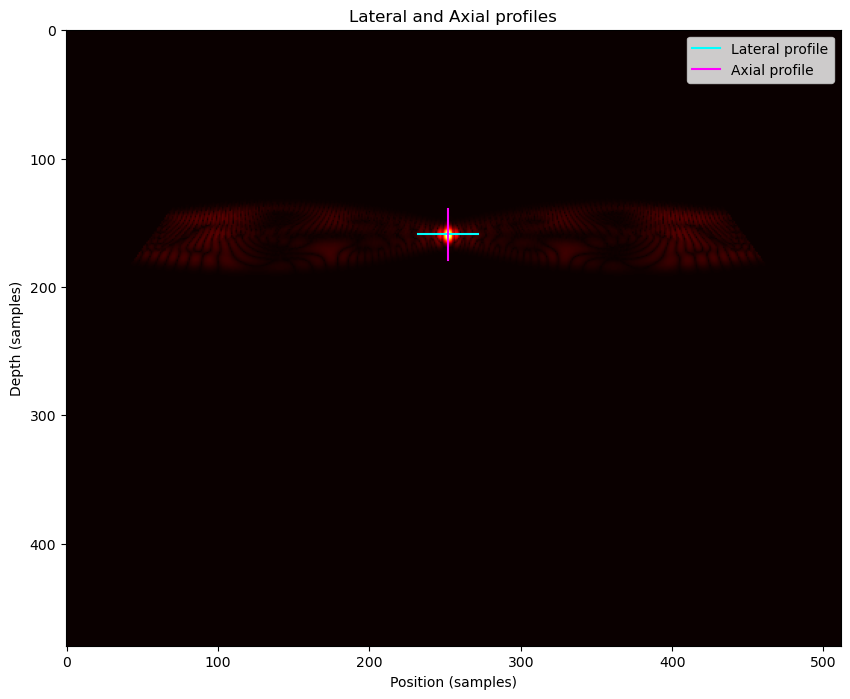

In [185]:
# profile_x0 = 246
# profile_y0 = 278
# lat_len = 100
# axial_len = 40
profile_x0 = 252
profile_y0 = 159
lat_len = 40
axial_len = 40


plt.figure(figsize = (10,8))
plt.imshow(np.sqrt(np.abs(bf_matrices[:,:,0])), cmap='hot', aspect='auto')

plt.plot([profile_x0 - lat_len/2, profile_x0 + lat_len/2], [profile_y0, profile_y0], color='cyan', linestyle='-', label='Lateral profile')
plt.plot([profile_x0, profile_x0], [profile_y0 - axial_len/2, profile_y0 + axial_len/2], color='magenta', linestyle='-', label='Axial profile')

plt.title("Lateral and Axial profiles")
plt.xlabel("Position (samples)")
plt.ylabel("Depth (samples)")
plt.legend()
plt.show()

/tmp/ipykernel_45159/3105761731.py:19: RuntimeWarning: divide by zero encountered in log10
  lateral_profile = 20 * np.log10(np.abs(lat) / np.max(np.abs(lat)))
/tmp/ipykernel_45159/3105761731.py:20: RuntimeWarning: divide by zero encountered in log10
  axial_profile = 20 * np.log10(np.abs(axial) / np.max(np.abs(axial)))


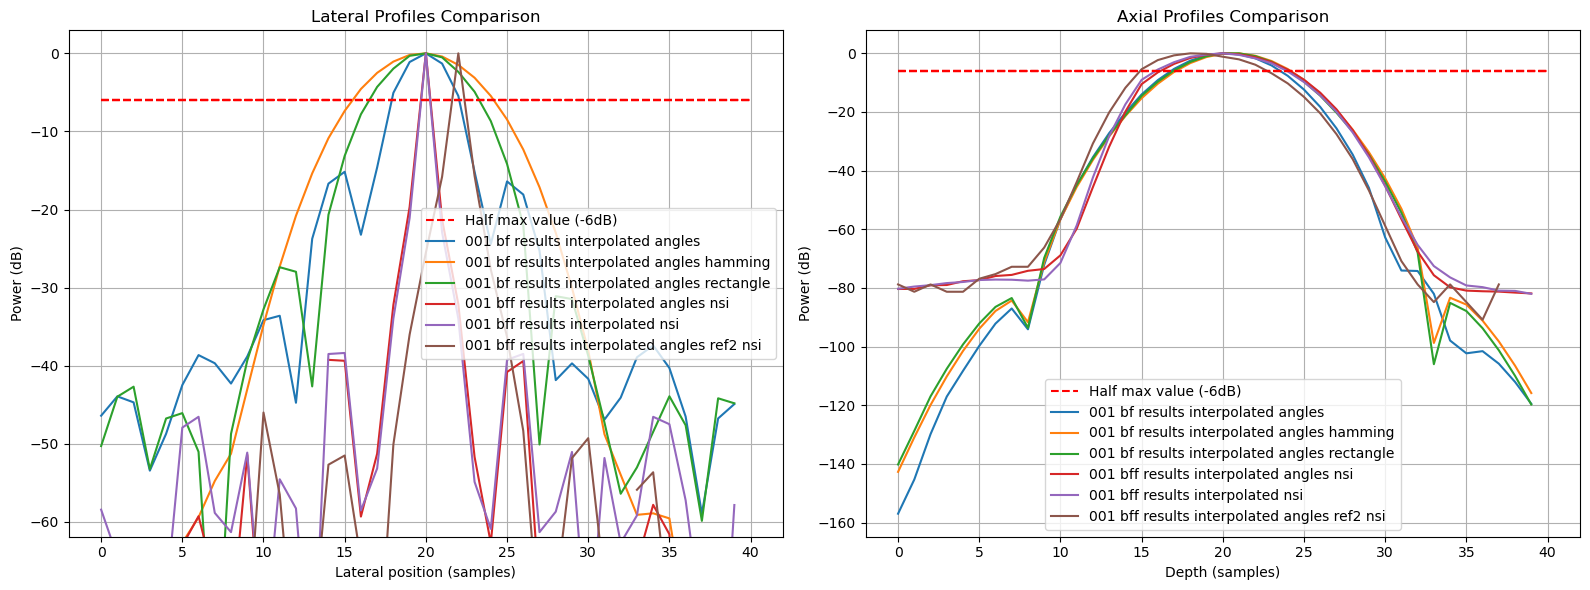

In [186]:
compare_resolutions(bf_matrices, params["image"]["dz"], params["image"]["dx"], labels, profile_x0=profile_x0, profile_y0=profile_y0, lat_len=lat_len, axial_len=axial_len)

# Highest energy region

In [187]:
def extract_highest_value_region_for_all(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices

In [188]:
def extract_highest_value_region(bf_matrices, submatrix_size=100):
    submatrices = []

    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        half_size = int(submatrix_size/2)
        row_start = row - half_size if row - half_size >= 0 else 0
        row_end = row + half_size if row + half_size < bf_matrices.shape[0] else bf_matrices.shape[0]
        col_start = col - half_size if col - half_size >= 0 else 0
        col_end = col + half_size if col + half_size < bf_matrices.shape[1] else bf_matrices.shape[1]

        submatrices.append(bf_matrices[row_start:row_end, col_start:col_end, i])
        
    return submatrices

In [189]:
submatrices_standalone = extract_highest_value_region(bf_matrices, submatrix_size=50)

In [190]:

def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

In [191]:
#plt.rcParams.update({'font.size': 22})

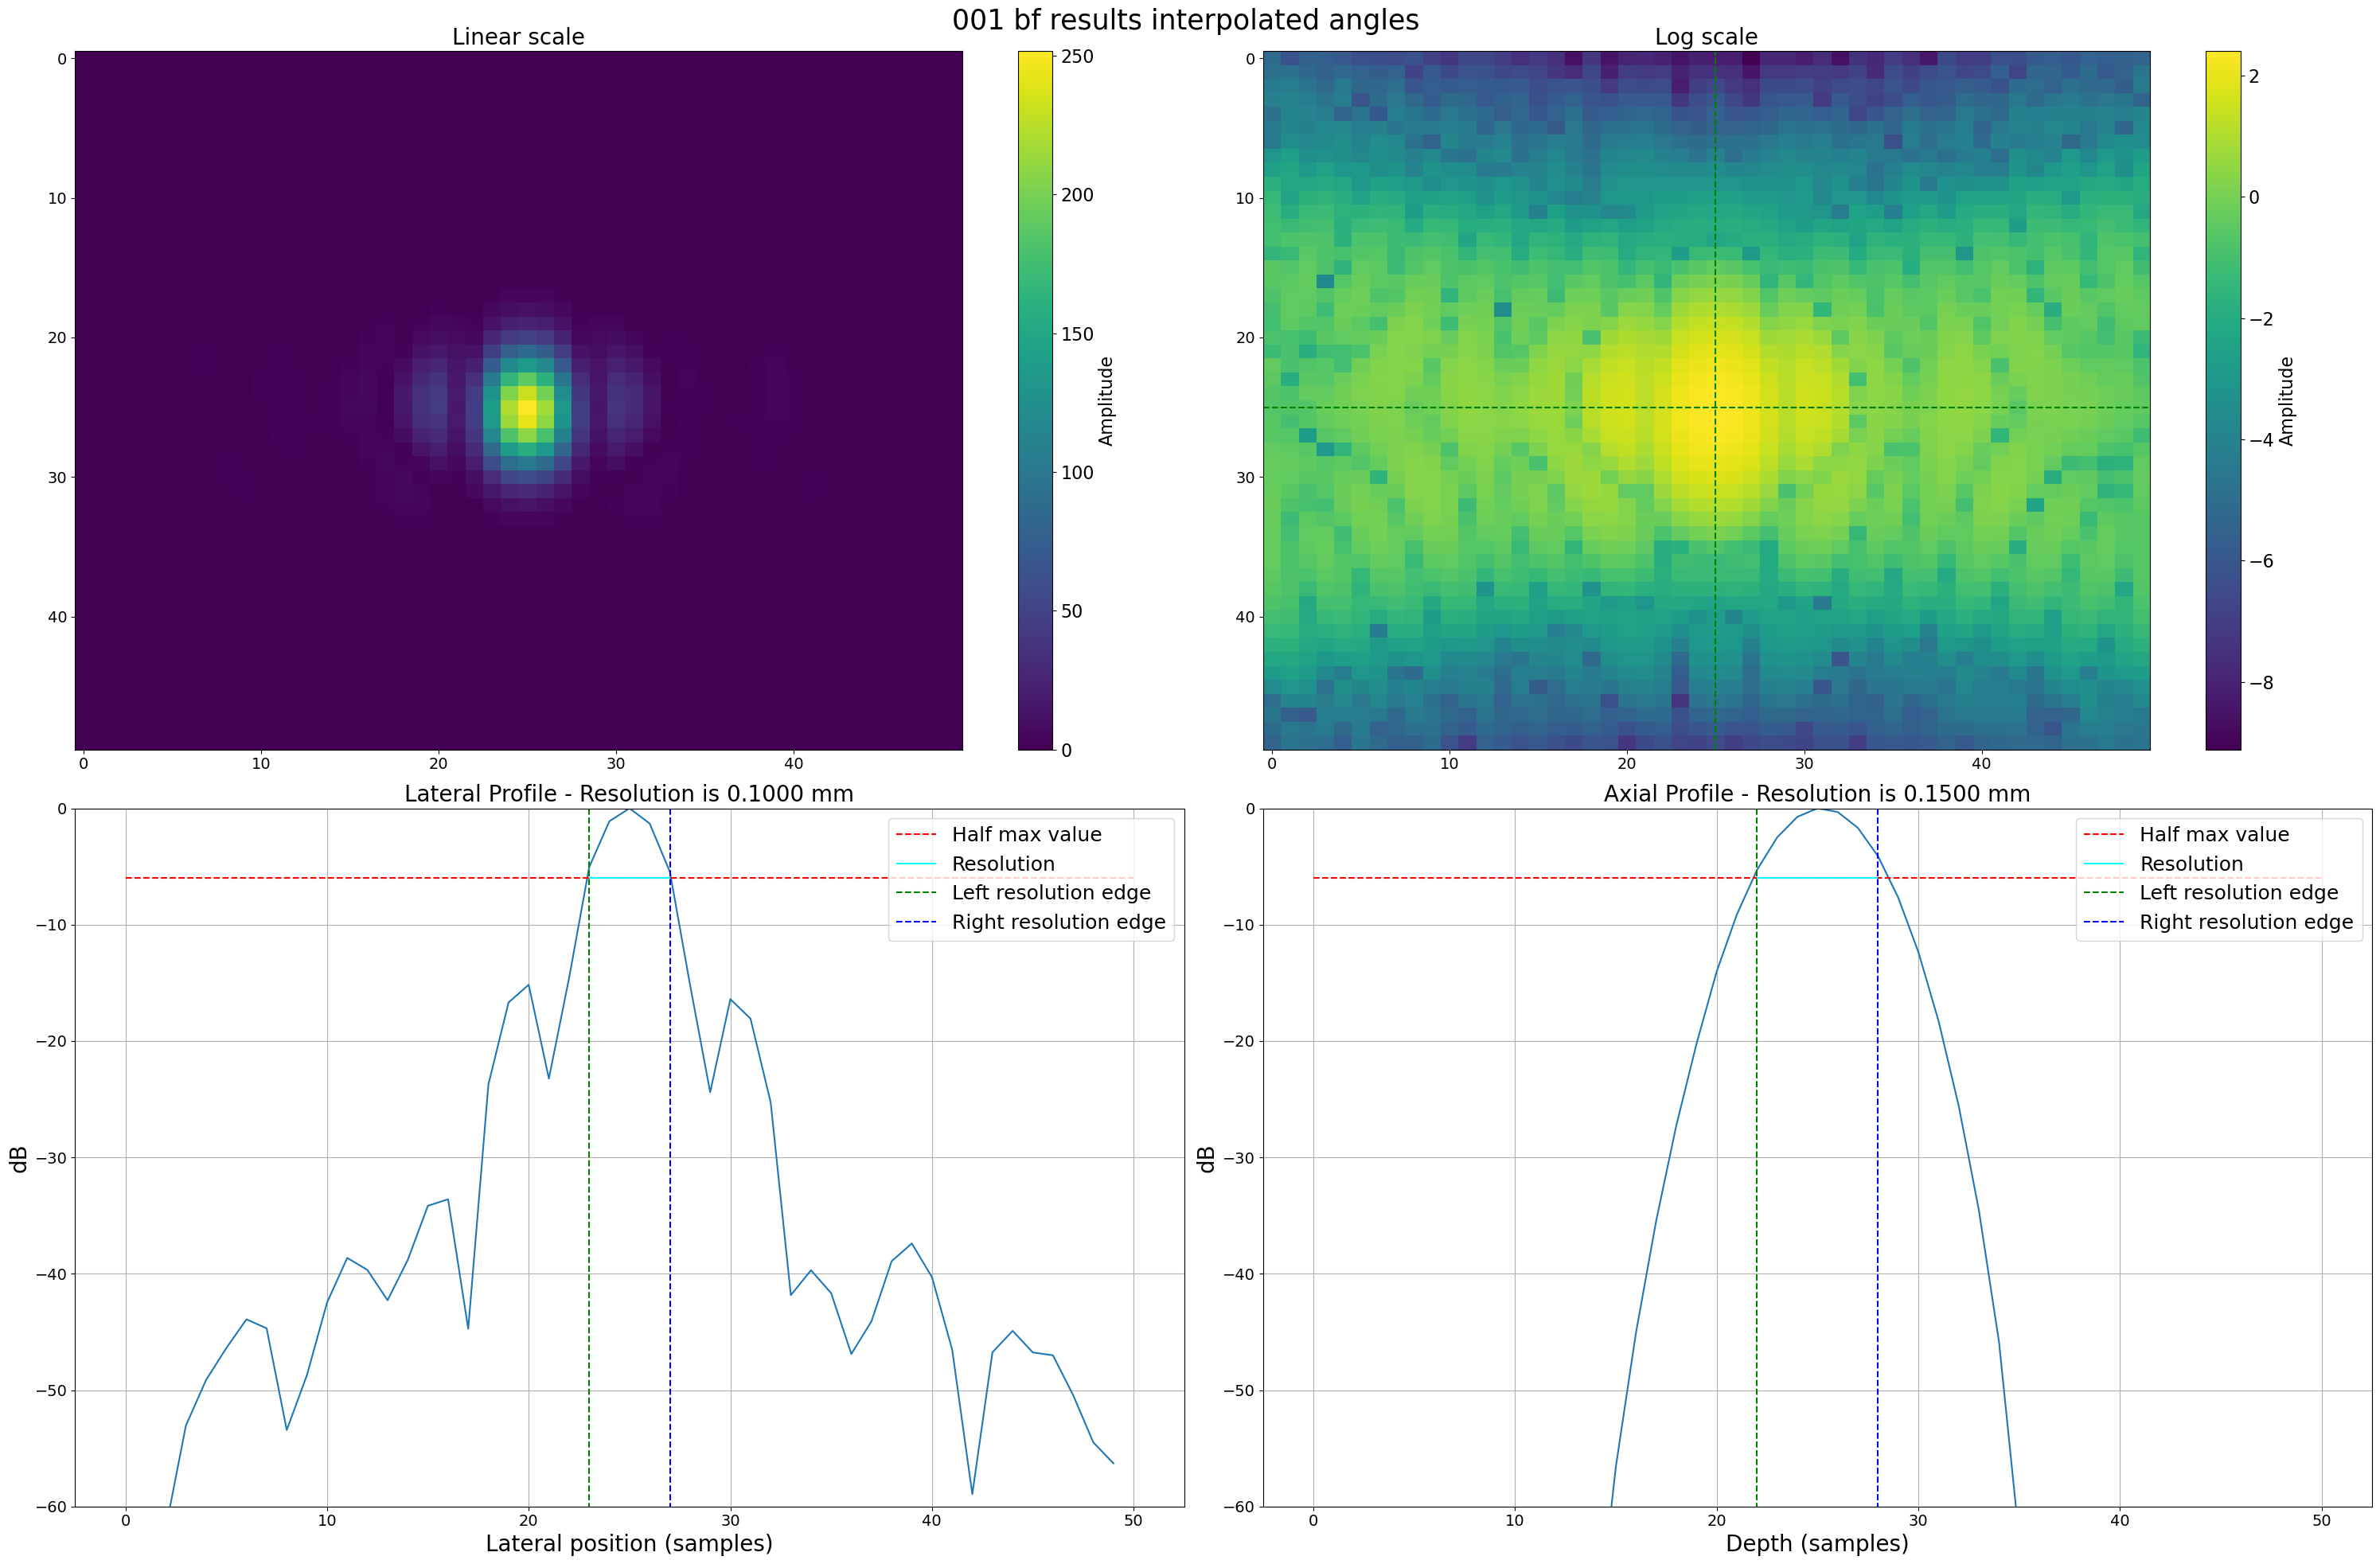

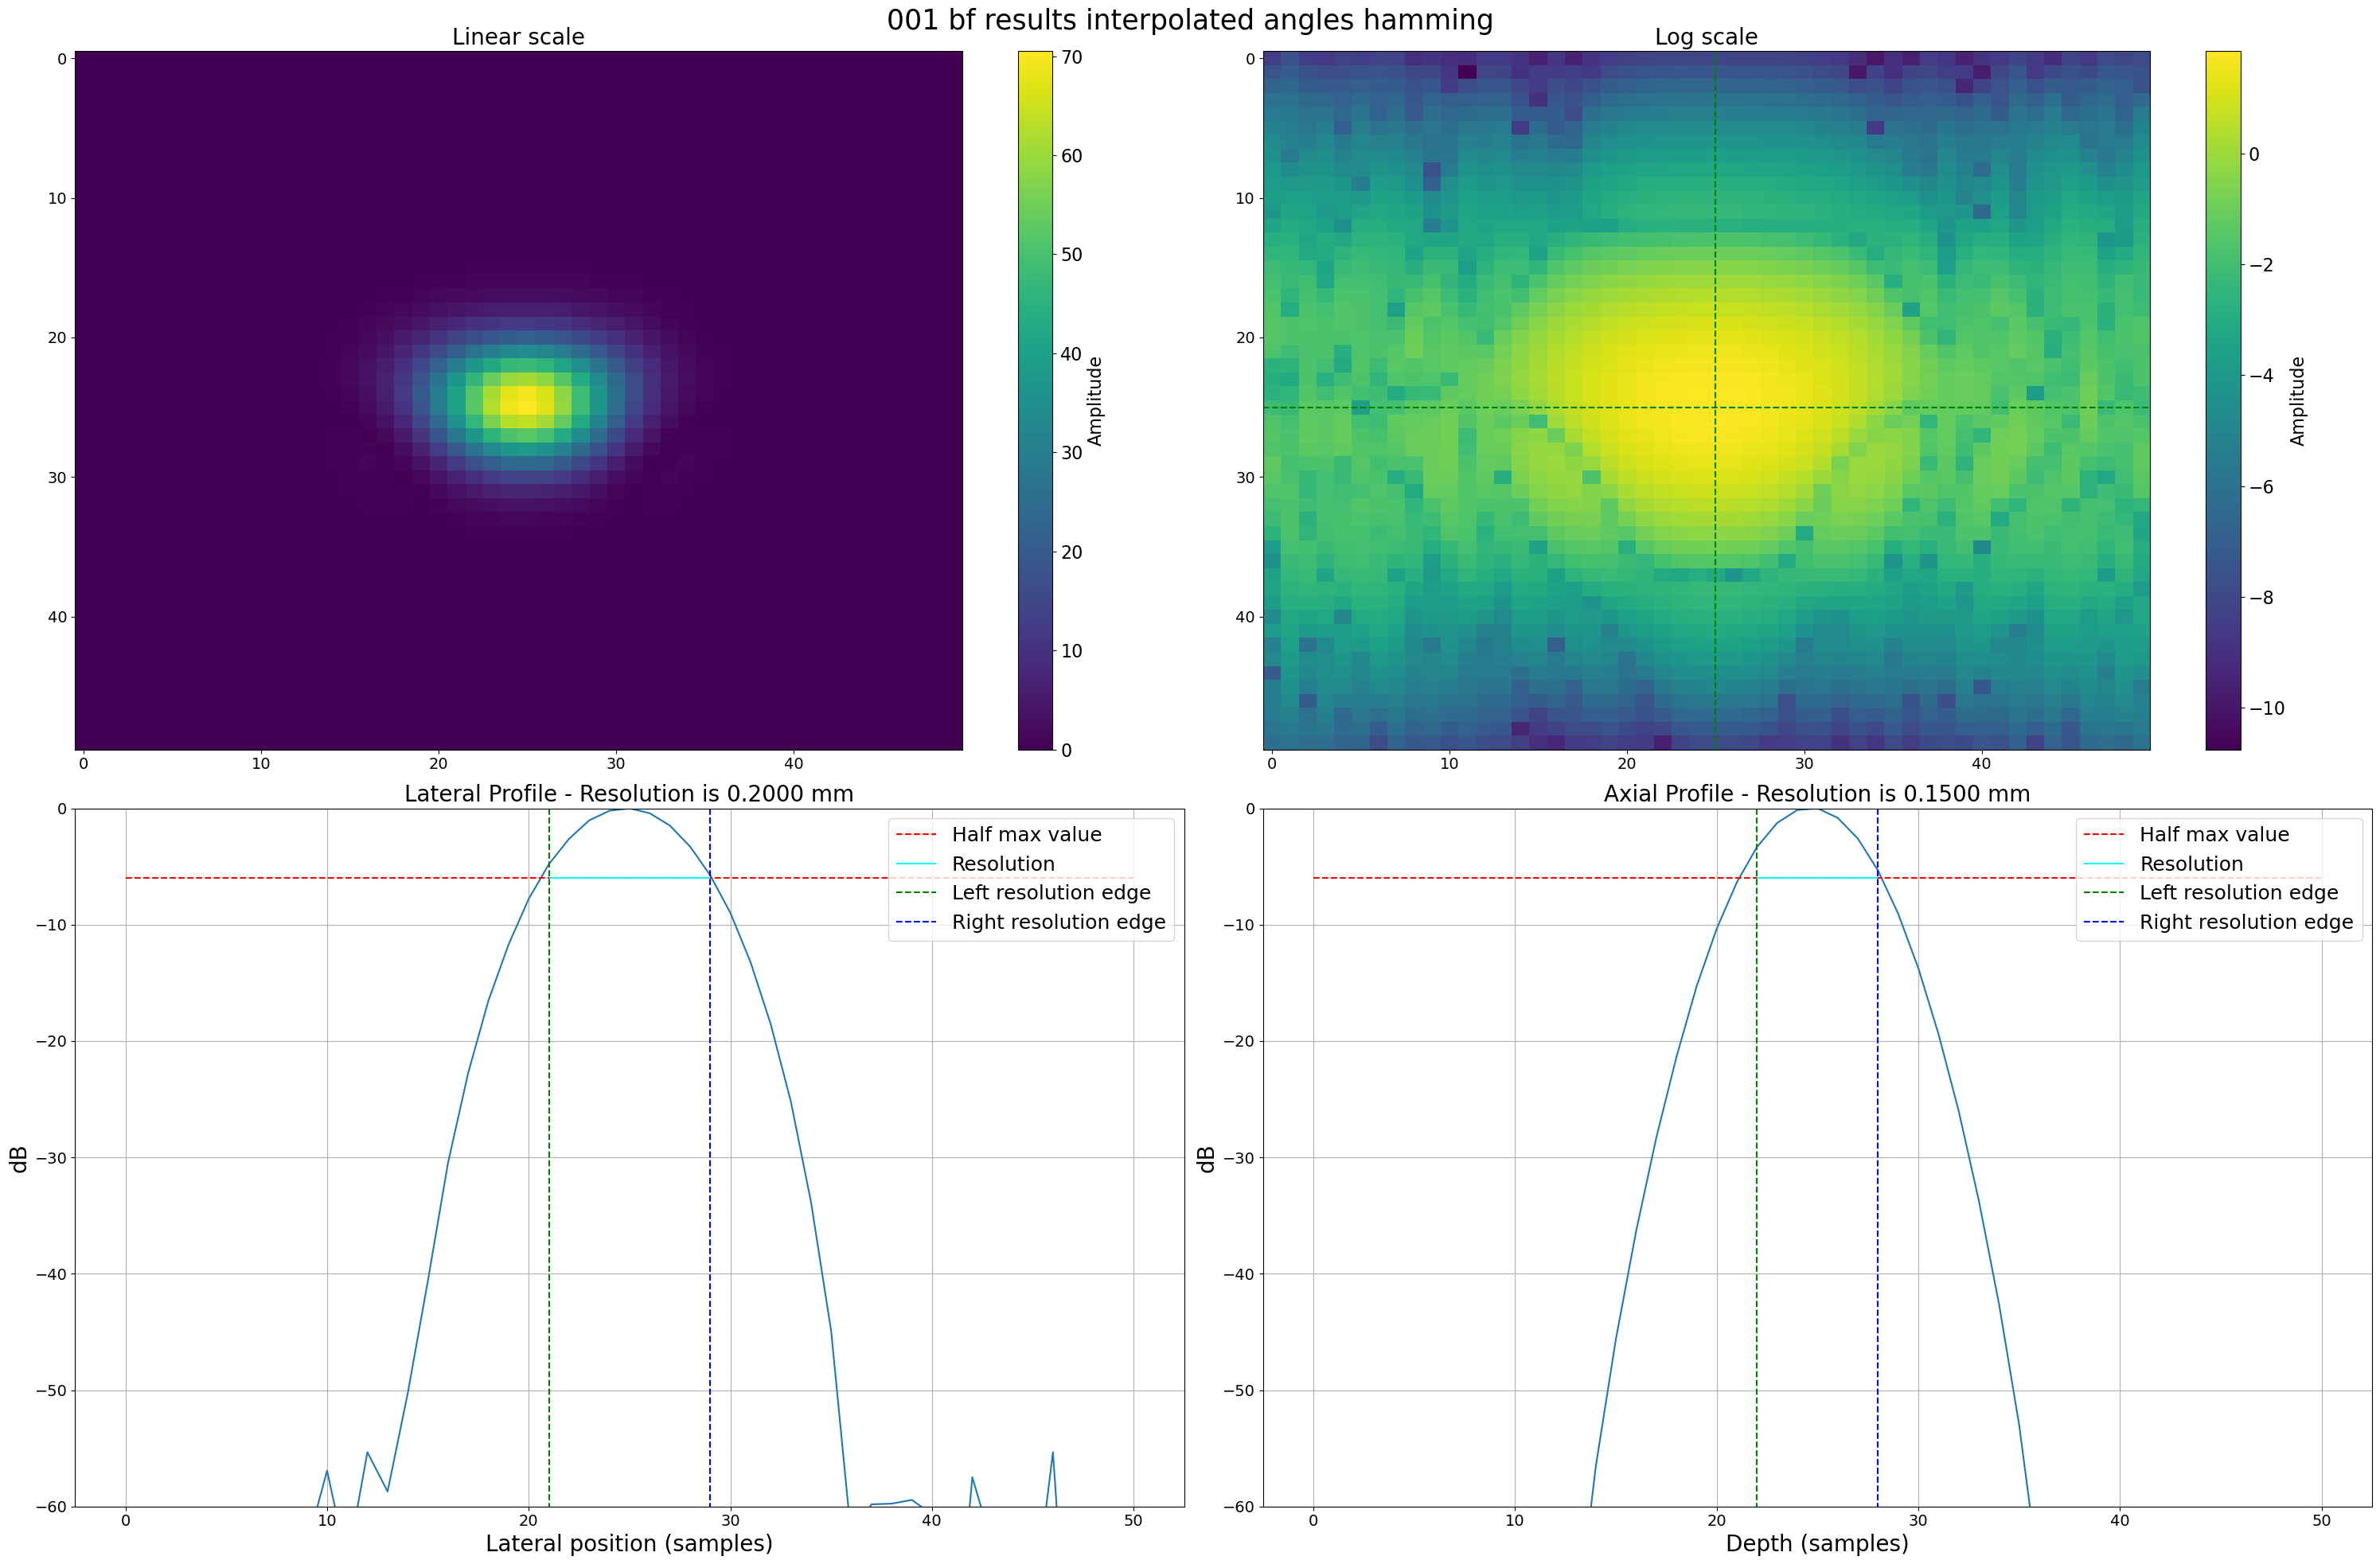

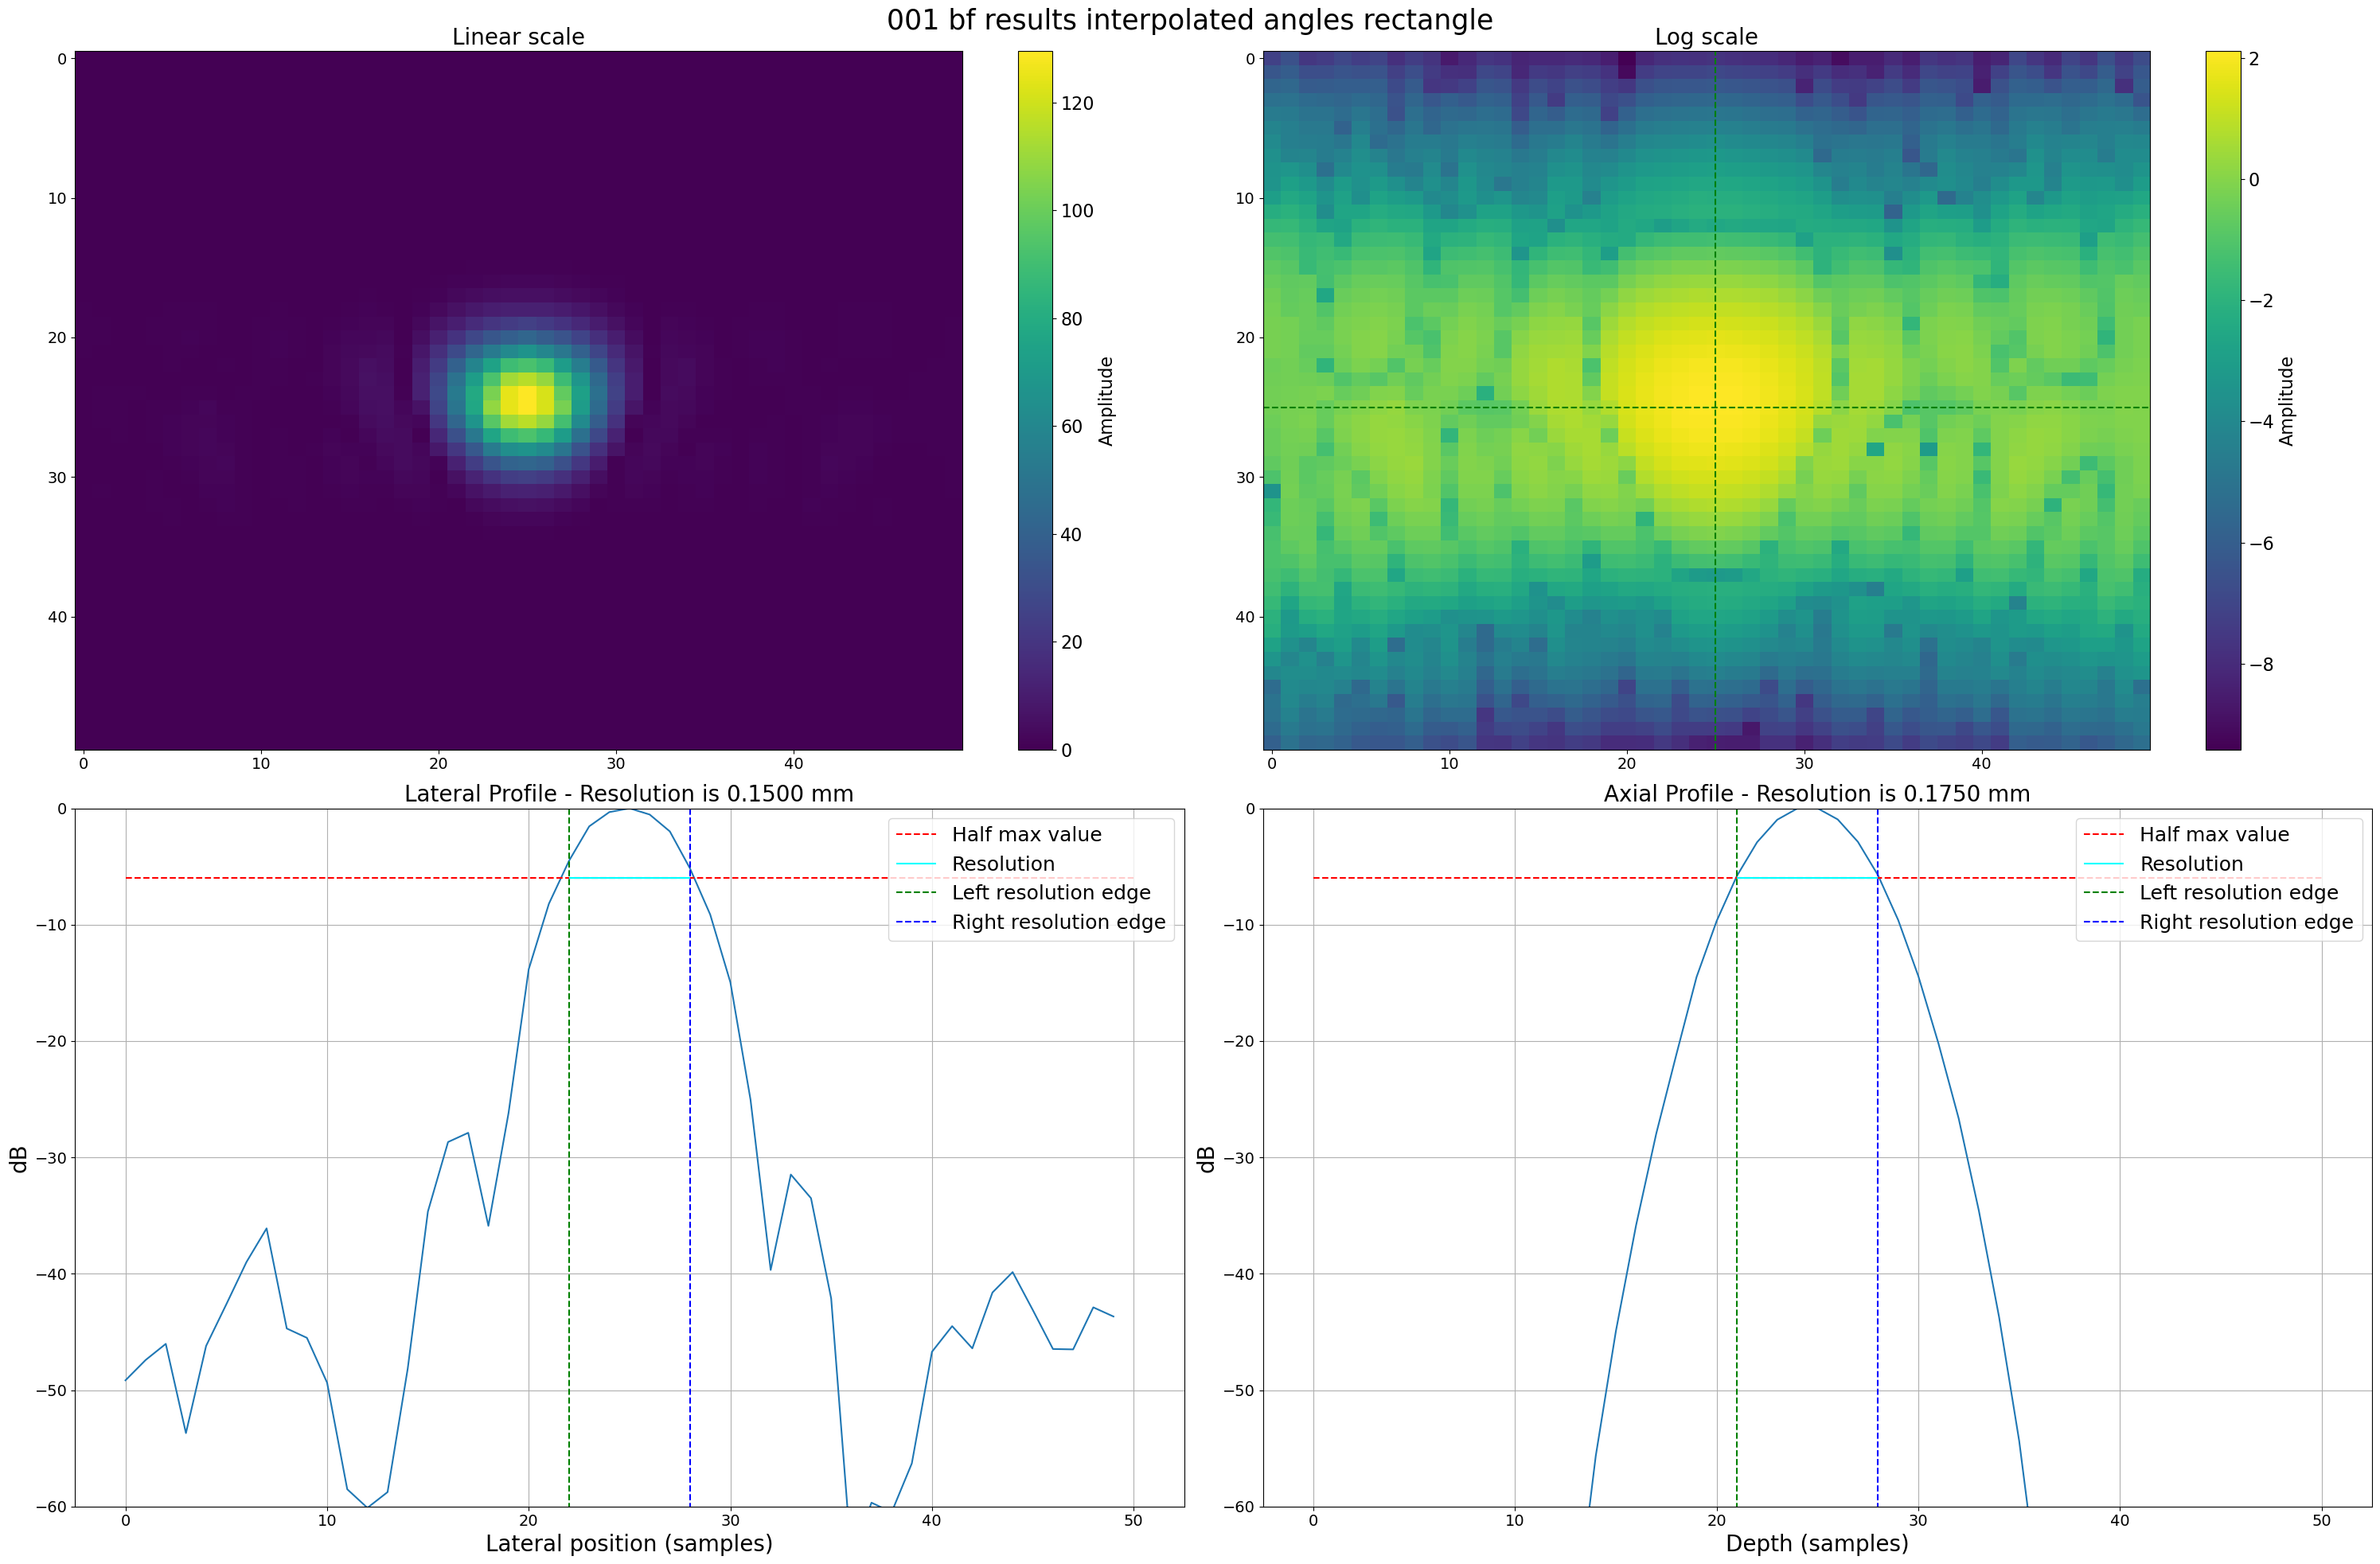

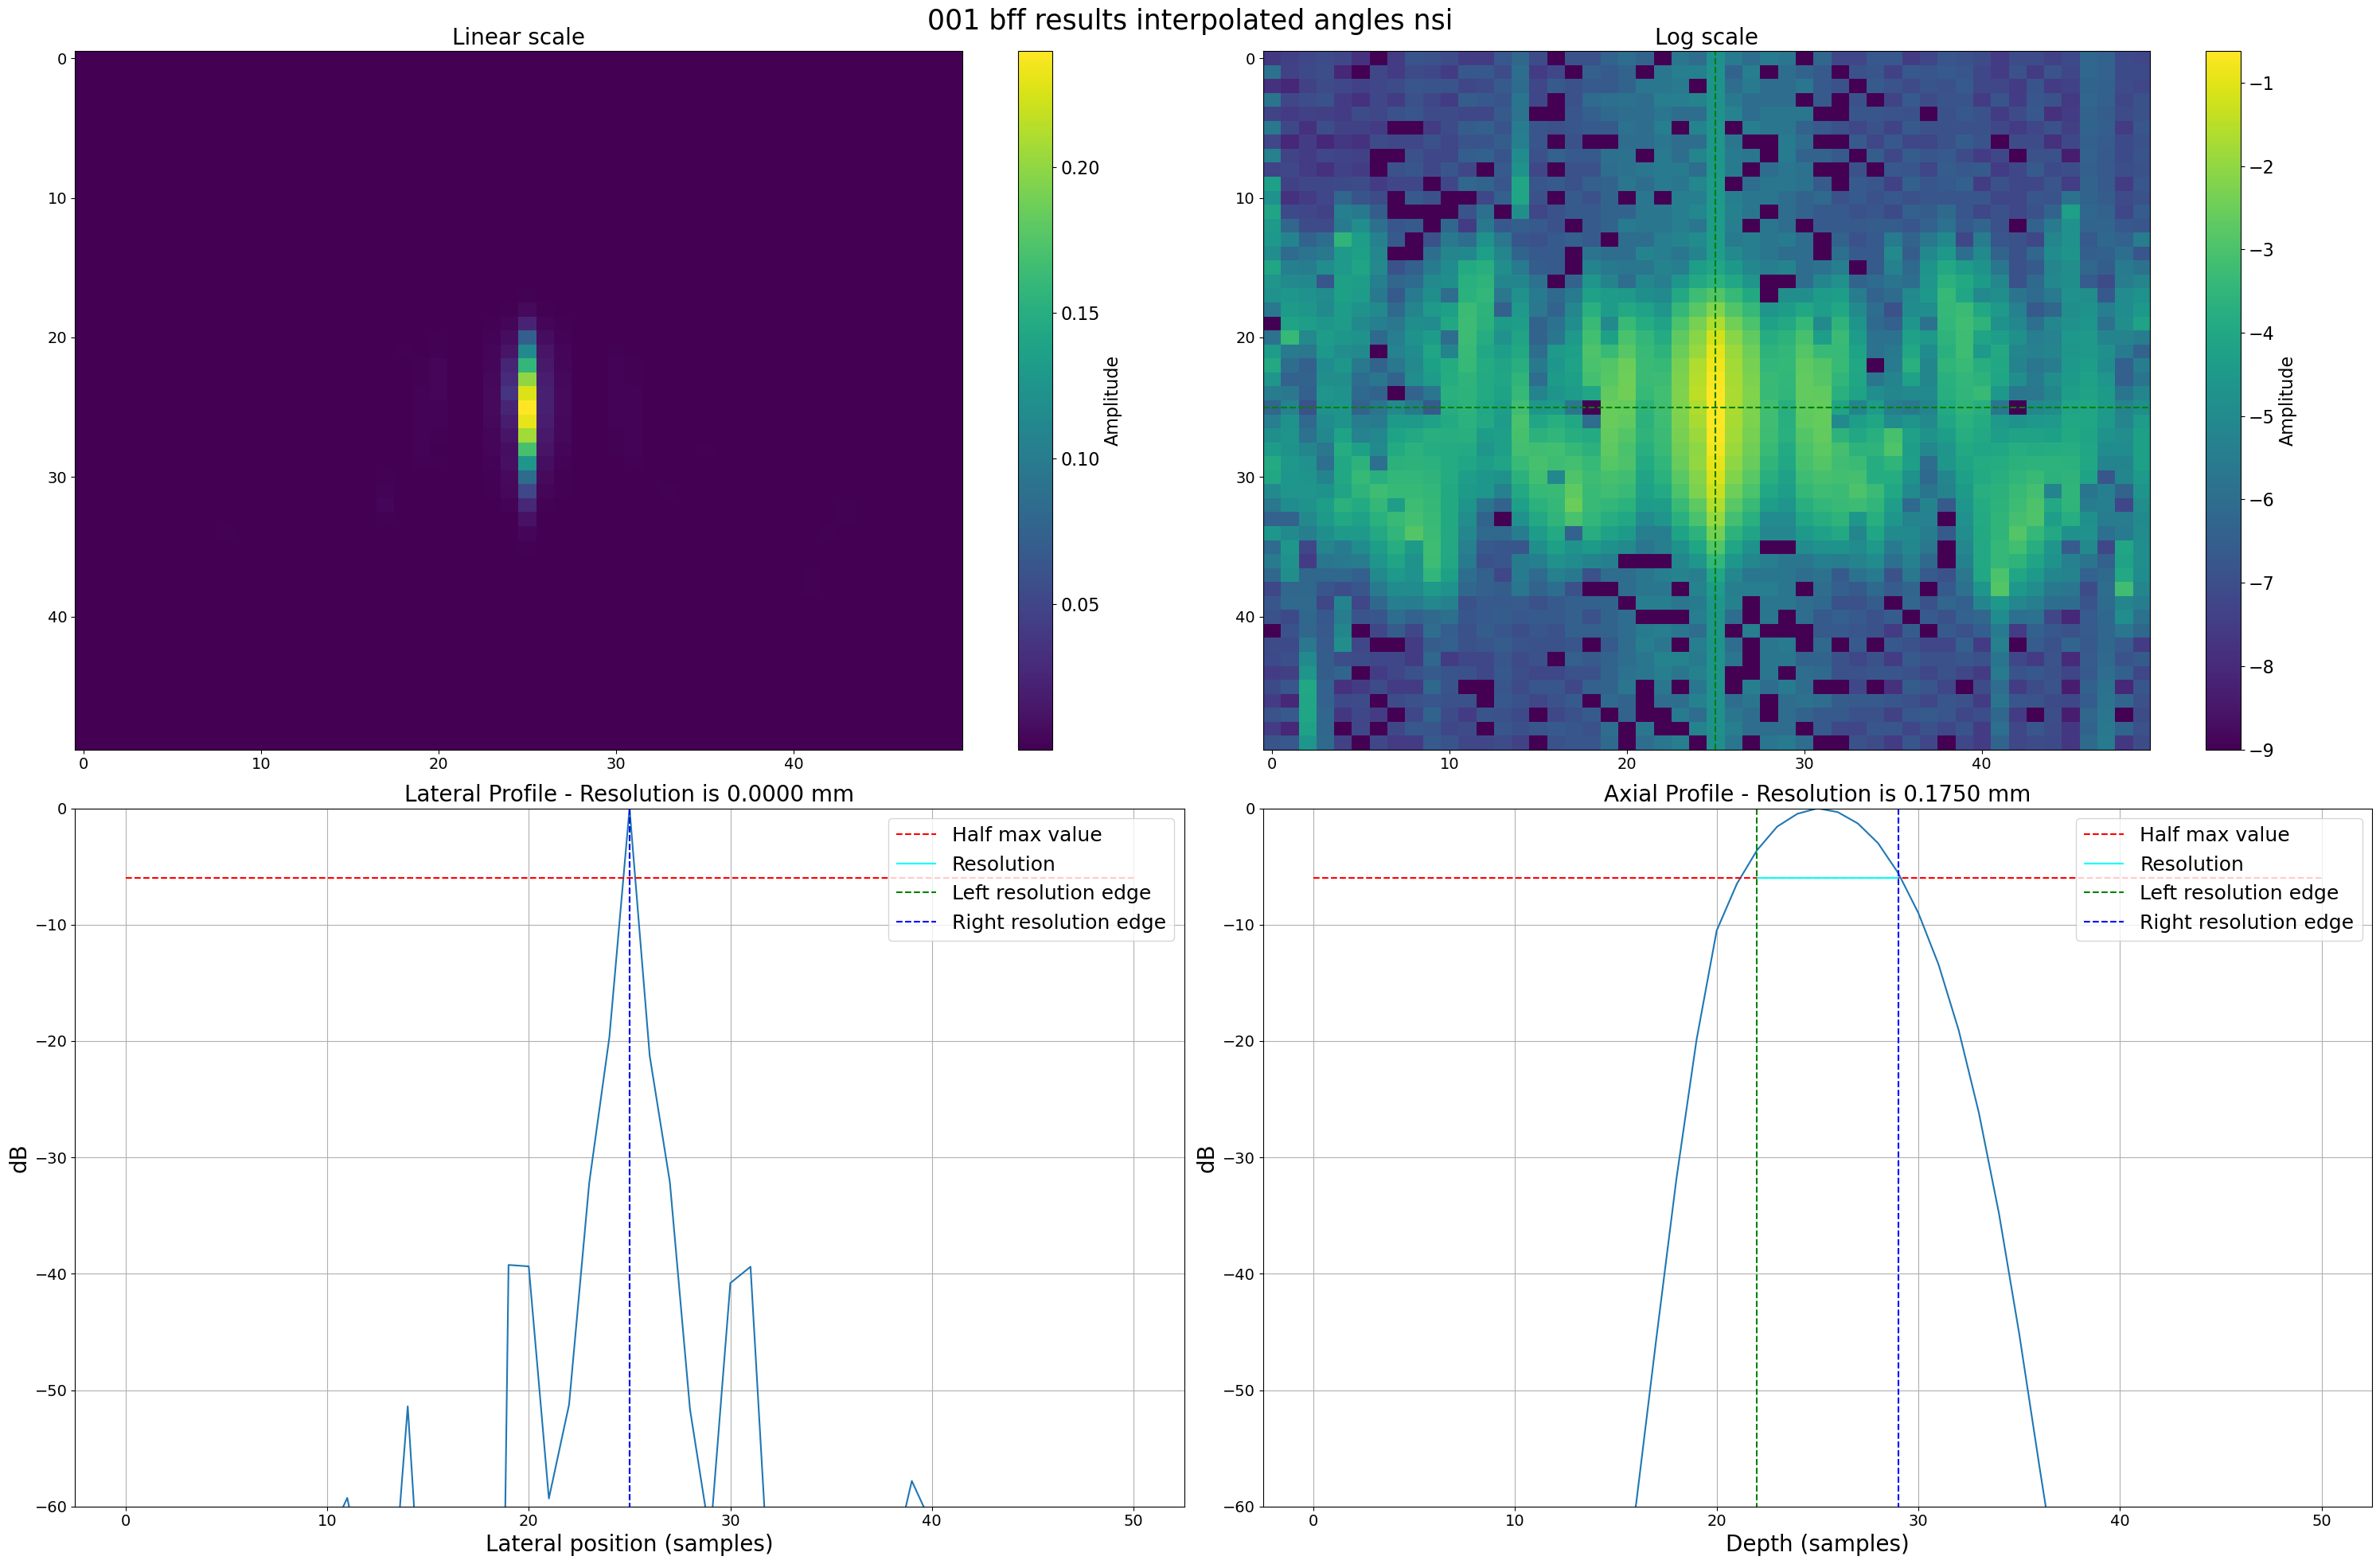

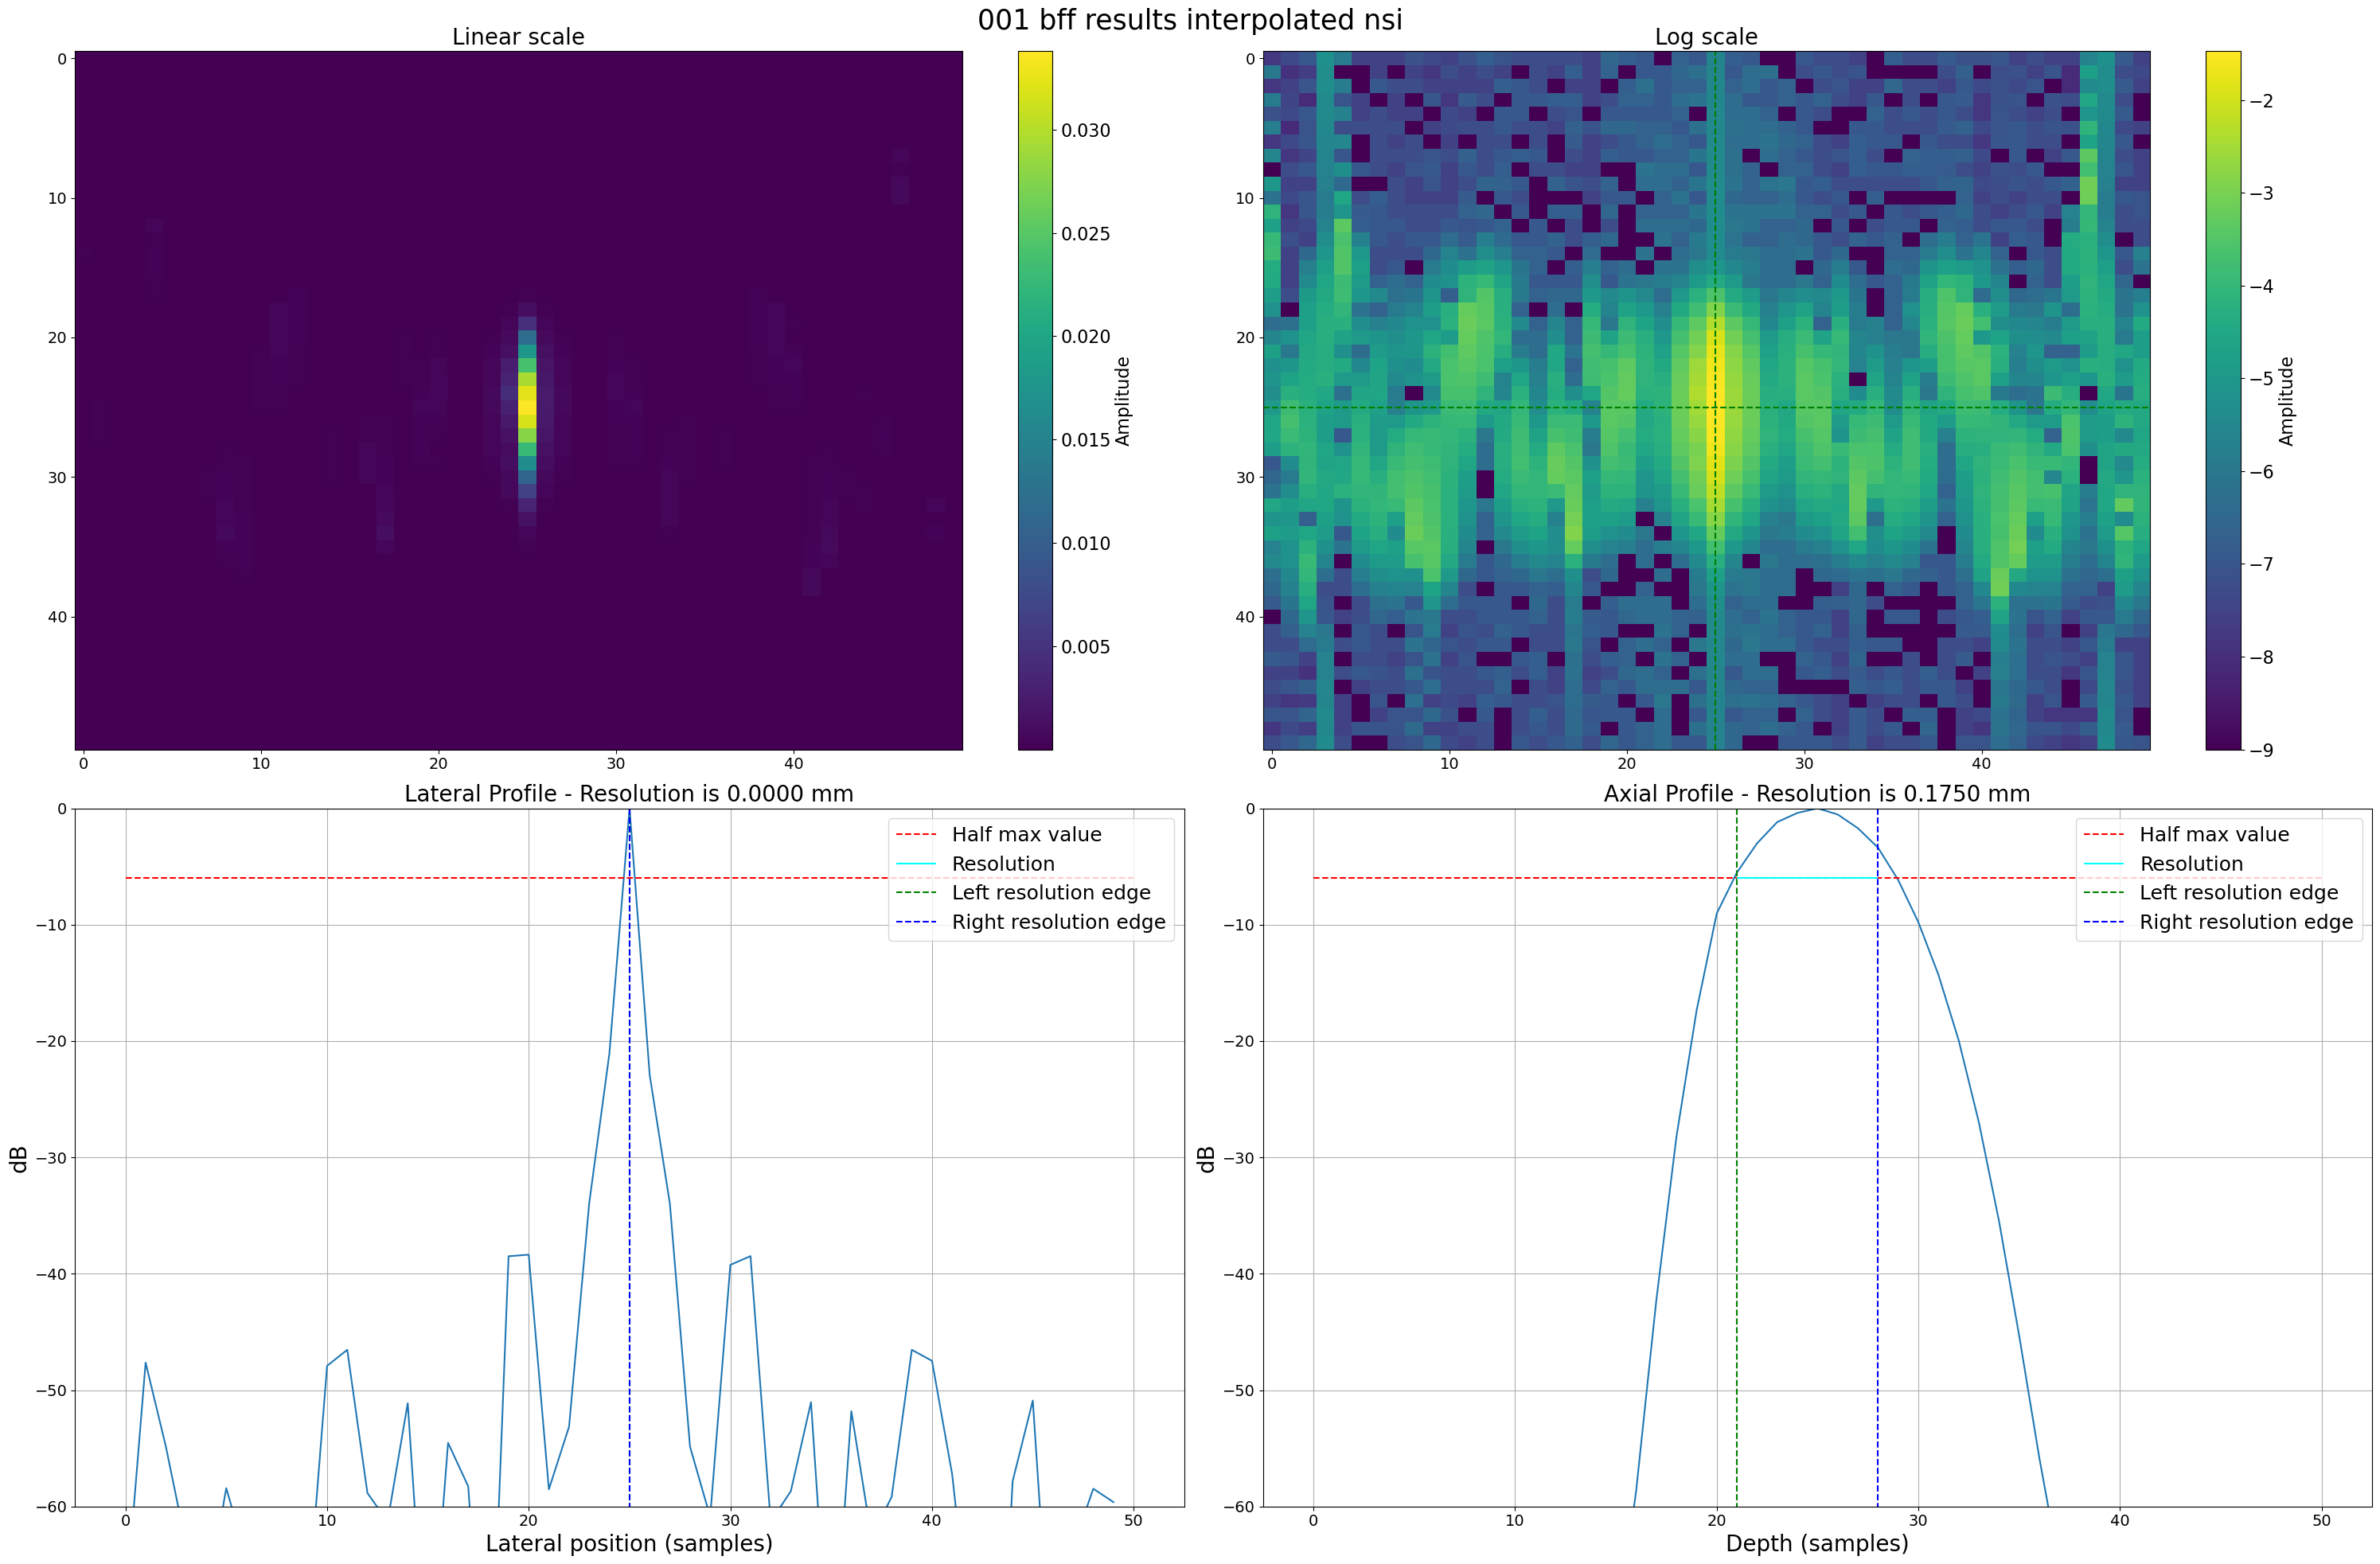

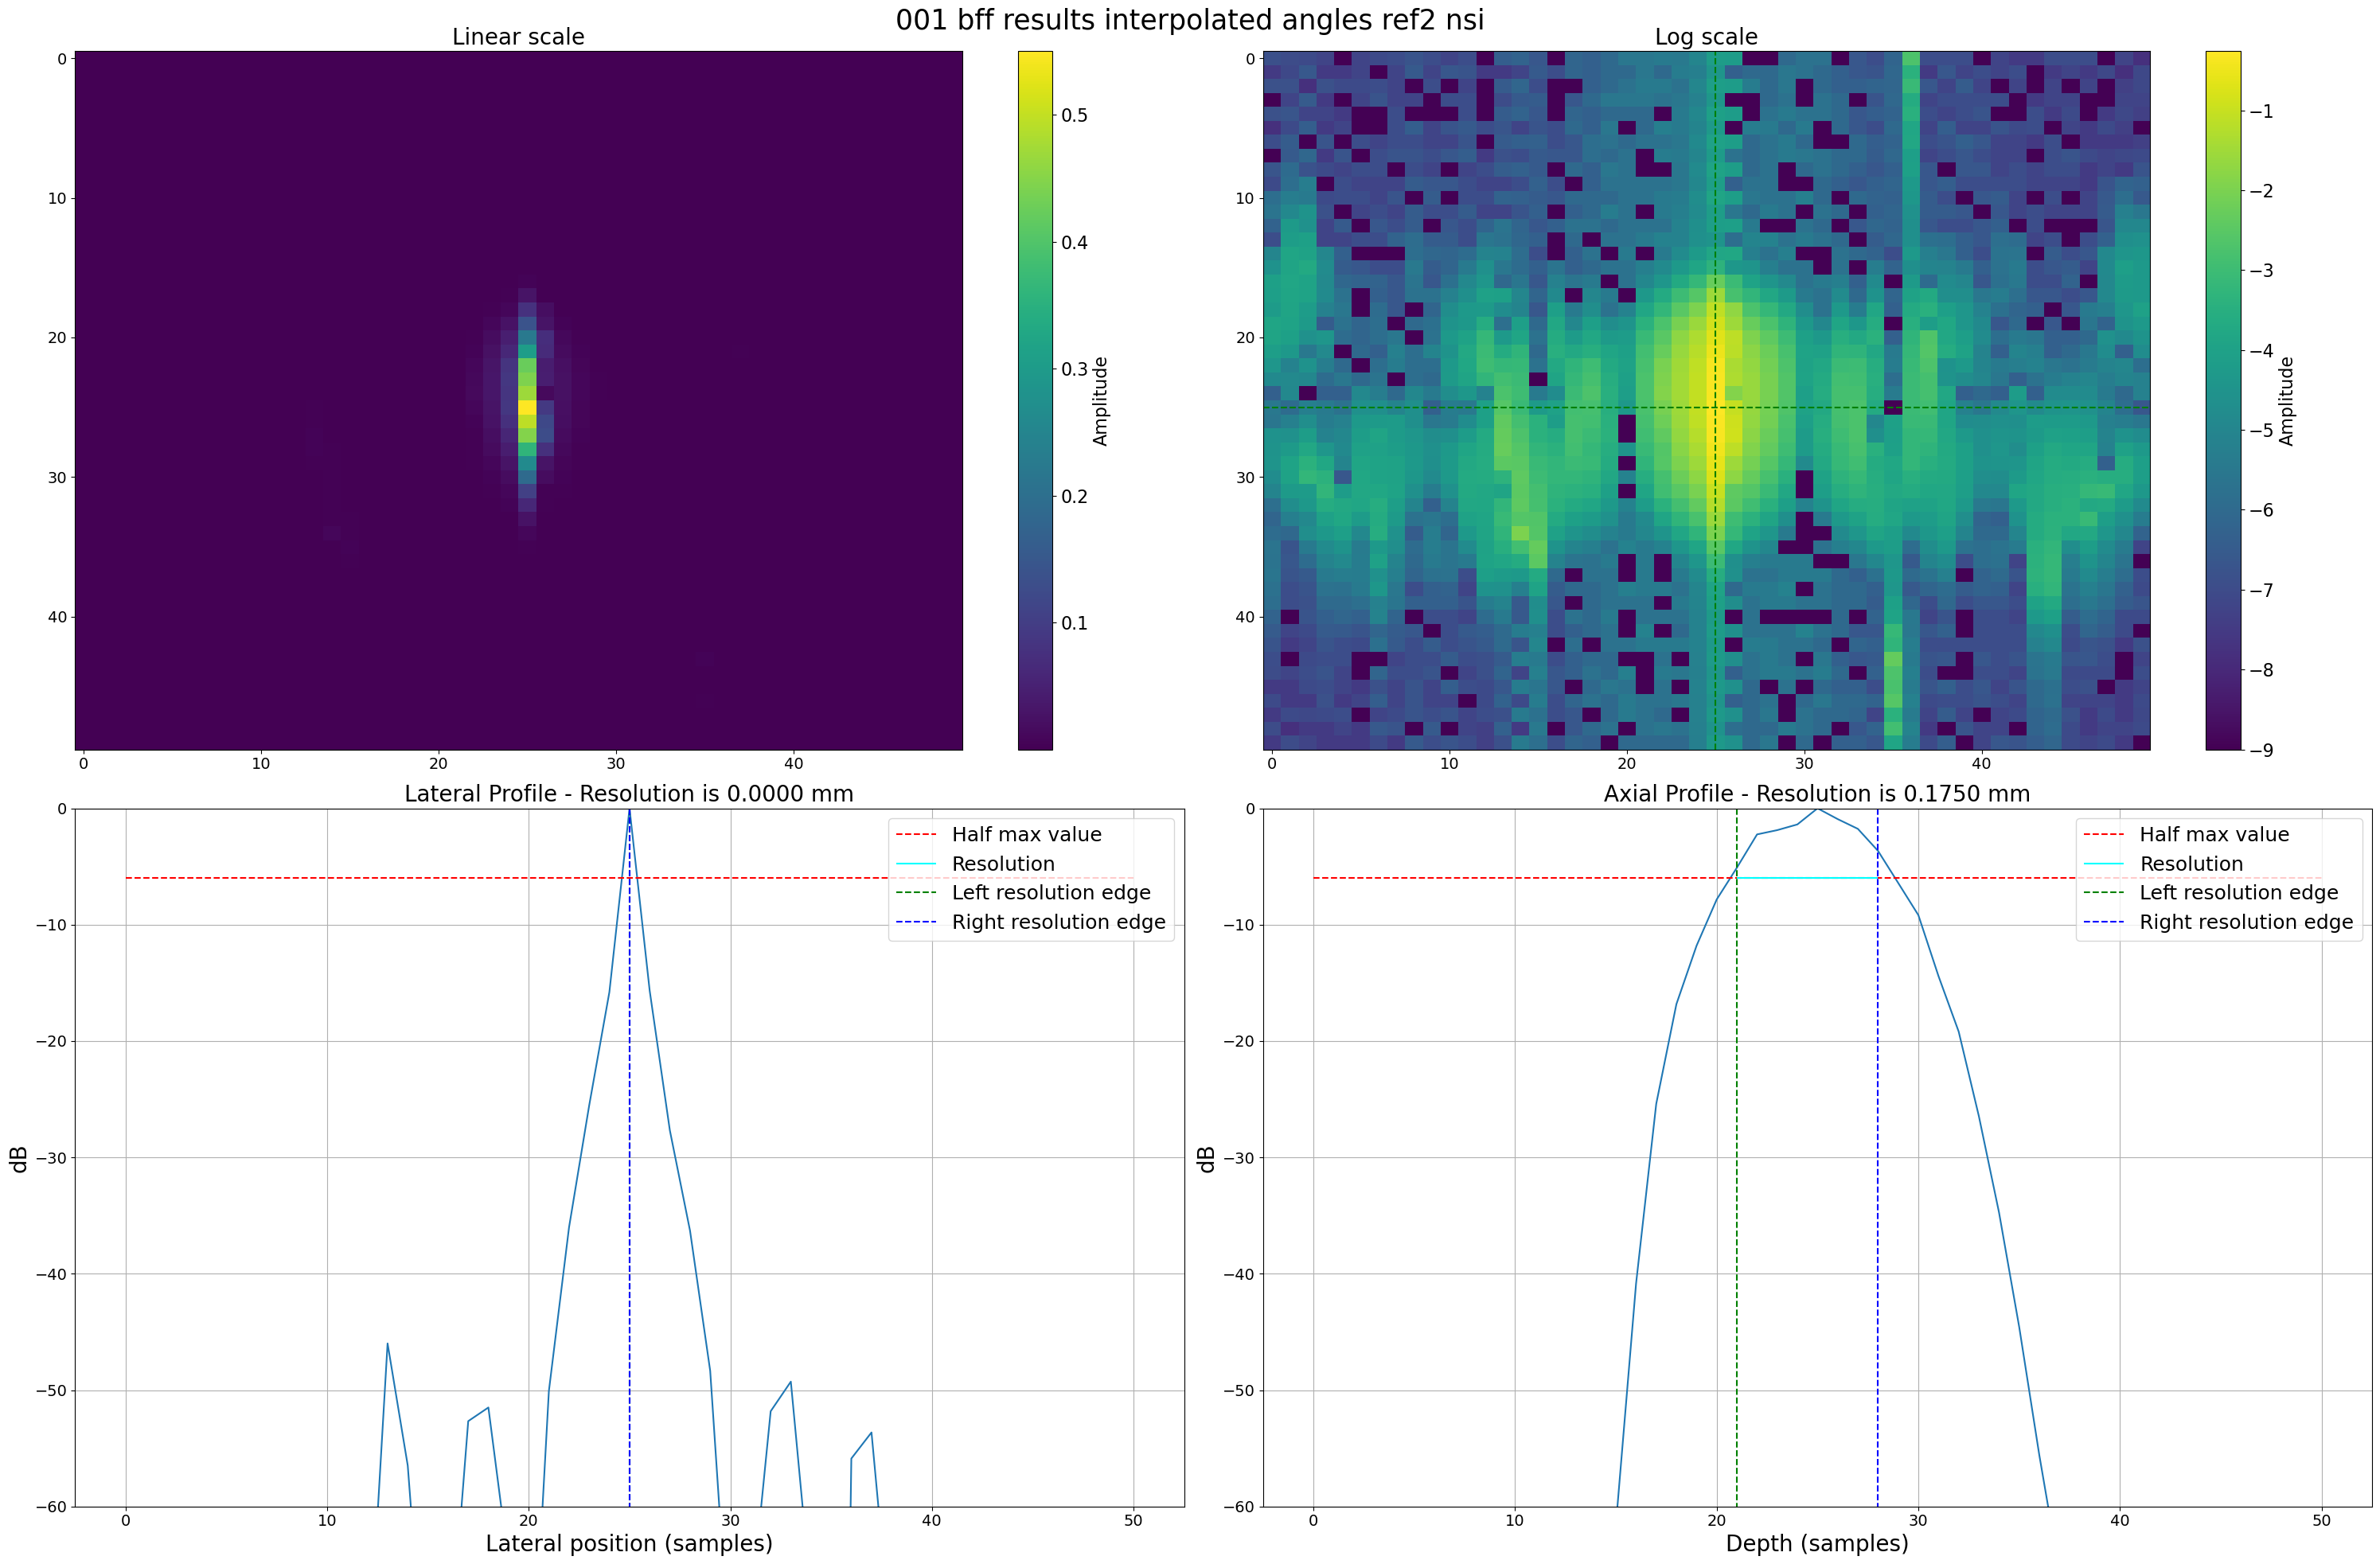

In [192]:
eps = 1e-9 

for idx, submatrix in enumerate(submatrices_standalone):
    submatrix += eps  # to avoid log(0) issues
    
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix)), submatrix.shape) #max value position

    fig, ax = plt.subplots(2,2, figsize=(30, 20))

    # visulization of high energy zone
    im0 = ax[0,0].imshow(np.abs(submatrix), cmap='viridis', aspect='auto')
    ax[0,0].set_title("Linear scale", fontsize=20)
    cbar0 = plt.colorbar(im0, label="Amplitude", ax=ax[0,0])
    cbar0.ax.tick_params(labelsize=16)
    cbar0.set_label("Amplitude", fontsize=16)

    #log view of high energy zone 
    im1 = ax[0,1].imshow(np.log10(np.abs(submatrix)), cmap='viridis', aspect='auto')
    ax[0,1].set_title("Log scale", fontsize=20)
    ax[0,1].axhline(y=max_val_row, color='g', linestyle='--')
    ax[0,1].axvline(x=max_val_col, color='g', linestyle='--')
    cbar1 = plt.colorbar(im1, label="Amplitude", ax=ax[0,1])
    cbar1.ax.tick_params(labelsize=16)
    cbar1.set_label("Amplitude", fontsize=16)

    #visualization of lateral profile (Lateral res (horizontal))
    lateral_profile =  20 * np.log10(np.abs(submatrix[max_val_row, :]) / np.max(np.abs(submatrix[max_val_row, :]))) #we take values along the row with maximum value

    lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

    im2 = ax[1,0].plot(lateral_profile)
    ax[1,0].set_title(f"Lateral Profile - Resolution is {lat_res * params['image']['dx'] * 1e3:0.4f} mm", fontsize=20)
    ax[1,0].set_xlabel("Lateral position (samples)", fontsize=20)
    ax[1,0].set_ylabel("dB", fontsize=20)
    ax[1,0].grid(True)
    ax[1,0].hlines(-6, 0, lateral_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,0].hlines(-6, lat_left_idx, lat_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,0].vlines(lat_left_idx, 0, min(lateral_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,0].vlines(lat_right_idx, 0, min(lateral_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,0].legend(fontsize=18)
    ax[1,0].set_ylim(-60, 0)


    #visulization of axial resolution (vertical)
    axial_profile = 20 * np.log10(np.abs(submatrix[:, max_val_col]) / np.max(np.abs(submatrix[:, max_val_col]))) #we take values along the column with maximum value

    ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

    im3 = ax[1,1].plot(axial_profile)
    ax[1,1].set_title(f"Axial Profile - Resolution is {ax_res * params["image"]["dz"] * 1e3:0.4f} mm", fontsize=20)
    ax[1,1].set_xlabel("Depth (samples)", fontsize=20)
    ax[1,1].set_ylabel("dB", fontsize=20)
    ax[1,1].grid(True)
    ax[1,1].hlines(-6, 0, axial_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,1].hlines(-6, ax_left_idx, ax_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,1].vlines(ax_left_idx, 0, min(axial_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,1].vlines(ax_right_idx, 0, min(axial_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,1].legend(fontsize=18)
    ax[1,1].set_ylim(-60, 0)

    fig.suptitle(labels[idx], fontsize=25)

    ax[0,0].tick_params(axis='both', labelsize=14)
    ax[0,1].tick_params(axis='both', labelsize=14)
    ax[1,0].tick_params(axis='both', labelsize=14)
    ax[1,1].tick_params(axis='both', labelsize=14)

    plt.tight_layout()
    plt.show()